# Lab 6 - Sentiment Analysis: Tweets

Do a sentiment analysis on the [syedkhalid076/Sentiment-Analysis](https://huggingface.co/datasets/syedkhalid076/Sentiment-Analysis) dataset. This dataset contains tweets (use only 10k samples for train dataset).

This dataset is designed for sentiment analysis tasks, providing labeled examples across three sentiment categories:
- 0: Negative
- 1: Neutral
- 2: Positive

## Import Libraries

In [40]:
# import required libraries
import matplotlib.pyplot as plt
import nltk
import pandas as pd
import seaborn as sns
import spacy
from datasets import load_dataset
from nltk.tokenize.toktok import ToktokTokenizer
from sklearn.model_selection import train_test_split



## Load Data

Loading code from the brief, with its `your-dataset-path` placeholder replaced by the dataset's Hugging Face id.

In [41]:
# Load the dataset
dataset = load_dataset('syedkhalid076/Sentiment-Analysis')

# Access splits
train_data = dataset['train']
validation_data = dataset['validation']
test_data = dataset['test']

# Example: Printing a sample
print(train_data[0])

Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields


{'text': 'almost got in a giant car accident on the 101', 'label': 0}


Convert the splits to DataFrames, using a random sample of 10k rows, stratified. Validation and test are kept in full.

In [42]:
# convert splits to dataframes, keeping a stratified 10k training sample
full_train_df = train_data.to_pandas()
train_df, _ = train_test_split(
    full_train_df,
    train_size=10_000,
    stratify=full_train_df['label'],
    random_state=37,
)
train_df = train_df.reset_index(drop=True)
validation_df = validation_data.to_pandas()
test_df = test_data.to_pandas()

label_names = ['Negative', 'Neutral', 'Positive']

train_df.head()

,text,label
0,in the tiny events that could make a person wh...,2
1,remain curious about each other against all odds,2
2,"the overcooked , ham-fisted direction",0
3,i was so bored i decided to iron all my baju s...,1
4,nair 's attention to detail,2


## Exploratory Data Analysis

In [43]:
# run standard checks
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    10000 non-null  str  
 1   label   10000 non-null  int64
dtypes: int64(1), str(1)
memory usage: 926.0 KB


In [44]:
train_df.shape, validation_df.shape, test_df.shape

((10000, 2), (10499, 2), (10499, 2))

In [45]:
train_df.duplicated().sum()

np.int64(0)

In [46]:
train_df.isna().sum()

text     0
label    0
dtype: int64

In [47]:
train_df['label'].value_counts(normalize=True)

label
2    0.4817
0    0.3988
1    0.1195
Name: proportion, dtype: float64

### Text length

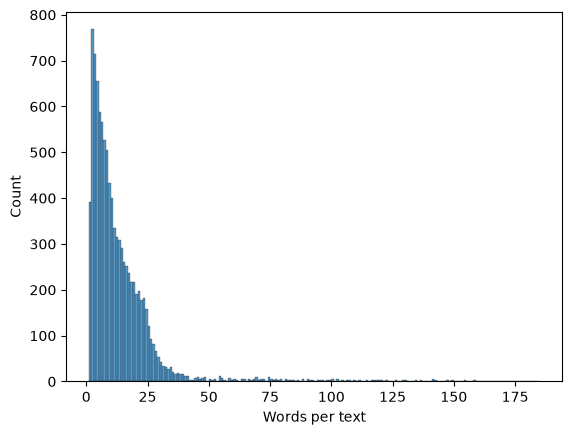

In [48]:
# number of words in each text
word_counts = train_df['text'].str.split().str.len()

# distribution of text length
sns.histplot(word_counts, binwidth=1)
plt.xlabel('Words per text')
plt.show()

## Text Pre-Processing and Normalisation

Cleaning and normalising the text before modelling.

In [49]:
# normaliser set-up, from the lecture's text_normaliser.py
nlp = spacy.load('en_core_web_sm')
tokenizer = ToktokTokenizer()
stopword_list = nltk.corpus.stopwords.words('english')
stopword_list.remove('no')
stopword_list.remove('not')

## 1. Use the two approaches covered in class and compare them with the best. (classifier and use the linguistic resource)

### Approach 1: Supervised Classifier

### Approach 2: Lexicon-Based Model (Linguistic Resource)

### Comparison

## 2. Notice that the text in the dataset is very short in some cases, so the accuracy of models may be relatively low.

Briefly discuss how you can potentially address this problem (short text).